# Noise PSD from the randoms cut: series 07221203_2025, dump F0001

Aim: redo the noise power spectrum of **Note 3** with a better-motivated set of noise traces. Note 3 averaged 14 traces from a 21-trace selection that mixed two detectors and was biased toward traces whose baseline scatter was inflated by the leading glitch samples. Here the traces are the **randoms cut**: the quiet-noise selection of Notes 2 and 2a (500-sample pretrigger window, Tight excursion band, `log10(bstd) < 0.5`) restricted to events recorded as randoms.

Everything is Detector 0 / Channel 0, as in Notes 2 and 3, and uses the shared `python/` library. Run with the `darkmatter_cli_env` kernel.

**Caveat carried over from Note 2a.** `pulse_cuts.randoms` assumes the dump's trigger-type labels are swapped (events recorded as `Physics` are taken to be randoms). This is a working assumption, not confirmed.

*Author: buddy. Draft, not yet a note.*

In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import csv
import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
from pulse_config import PulseConfig

import check_environment
check_environment.check()

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


[]

## 1. Load the dump and make the cut

`config_500` measures the baseline over the first 500 samples (so `dev`, the largest excursion, is measured only after sample 500), and skips the first 10 samples, which can carry an electronics glitch.

In [2]:
DUMP = "07221203_2025_F0001"
DETECTOR, CHANNEL = 0, 0
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10, sample_period_s=1.6e-6)

cdms = load_all_data(str(Path.home() / "idx" / DUMP))
ids, pulses = pio.load_channel_batch(cdms, pio.filter_by_detector(cdms.get_detector_ids(), DETECTOR), CHANNEL)
event = np.array([int(pio.event_id(i)) for i in ids])
trig = pio.trigger_types(cdms, ids)          # trigger label from the dump's .csv, one per trace
print(f"{len(ids)} traces, events {event.min()}-{event.max()}; trigger labels:",
      {t: int((trig == t).sum()) for t in np.unique(trig)})

1517 traces, events 10000-11569; trigger labels: {np.str_('Physics'): 1008, np.str_('Unknown'): 509}


## 2. The randoms cut

The cut is defined in this one cell, so it is easy to change. It is the Note 2a selection: Tight band (`log10(ratio)` in [0.5, 0.7)) plus `log10(bstd) < 0.5`, then `randoms`. Note 2a reports 179 traces before the trigger-label step and 141 after it for this detector and channel.

In [3]:
bstd_500 = pq.bstd(pulses, config_500)
quiet_noise = pc.excursion_band(pulses, config_500) & (np.log10(bstd_500) < 0.5)
sel_randoms = quiet_noise & pc.randoms(trig)          # <- the randoms cut
sel_real = quiet_noise & pc.real_triggers(trig)

print(f"quiet-noise selection:           {quiet_noise.sum()} traces   (Note 2a: 179)")
print(f"  of which randoms (the cut):    {sel_randoms.sum()} traces   (Note 2a: 141)")
print(f"  of which real triggers:        {sel_real.sum()} traces")
print(f"randoms cut: events {event[sel_randoms].min()}-{event[sel_randoms].max()}, "
      f"bstd median {np.median(bstd_500[sel_randoms]):.2f} counts")

quiet-noise selection:           179 traces   (Note 2a: 179)
  of which randoms (the cut):    141 traces   (Note 2a: 141)
  of which real triggers:        38 traces
randoms cut: events 10010-11433, bstd median 1.51 counts


C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\2340683059.py:3: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  sel_randoms = quiet_noise & pc.randoms(trig)          # <- the randoms cut
C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\2340683059.py:4: UserWarning: real_triggers is marked under_development: the other half of the randoms assumption: events recorded as 'Unknown' are taken to be real (pulse-triggered) events. Not confirmed; see `randoms`
  sel_real = quiet_noise & pc.real_triggers(trig)


## 3. Look at the traces

Thirty of the selected traces, baseline-subtracted, zoomed on the noise. A good noise set looks like featureless scatter around zero.

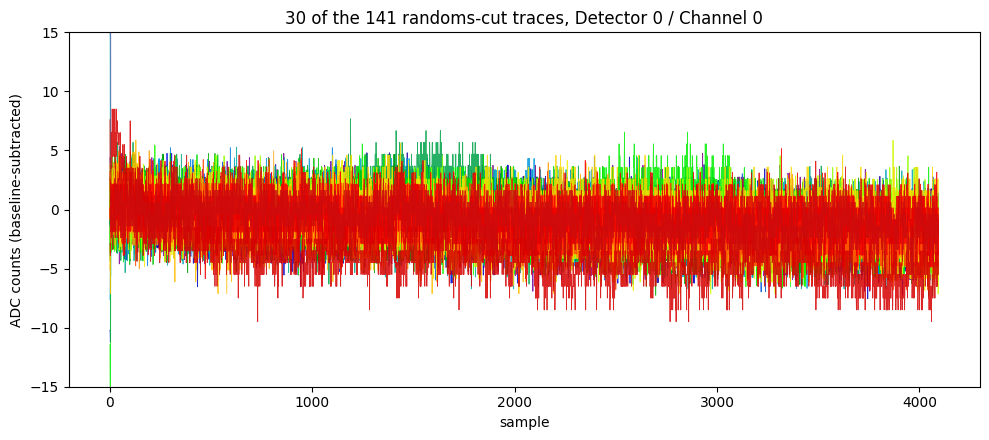

In [4]:
bl = pq.bline(pulses, config_500)
rng = np.random.default_rng(0)
pick = rng.choice(np.flatnonzero(sel_randoms), size=min(30, sel_randoms.sum()), replace=False)
colors = plt.cm.nipy_spectral(np.linspace(0.05, 0.95, len(pick)))

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, c in zip(pick, colors):
    ax.plot(pulses[i] - bl[i], linewidth=0.6, color=c, alpha=0.85)
ax.set_ylim(-15, 15)    # the leading glitch (up to hundreds of counts) runs off the plot
ax.set_xlabel("sample")
ax.set_ylabel("ADC counts (baseline-subtracted)")
ax.set_title(f"{len(pick)} of the {sel_randoms.sum()} randoms-cut traces, Detector {DETECTOR} / Channel {CHANNEL}")
fig.tight_layout()
plt.savefig(f'figures/chan0-traces-07221203_2025_F0001.png')
plt.show()


## 4. Power spectrum

Each trace is baseline-subtracted and its first 10 samples are trimmed before the FFT (the glitch would otherwise leak broadband power into the low bins). Two normalizations are shown:

- **raw** `|FFT|^2`, which is what Note 3 plotted, so the two can be compared directly;
- a **one-sided PSD in counts^2/Hz**, `2 * dt * |FFT|^2 / N`, with `dt` the sample period and `N` the number of samples (the DC bin is dropped). This is one common convention; check it against the thesis convention cited in Note 3 before using it for optimal filtering.

The shaded band is the 16th to 84th percentile of the individual traces at each frequency.

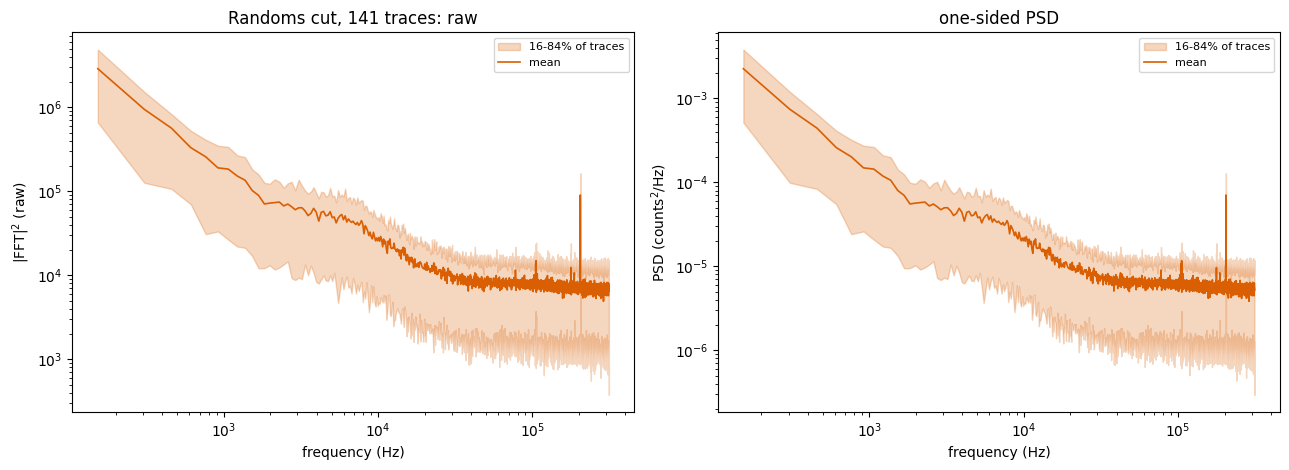

In [5]:
def processed(pulse_array):
    # baseline-subtract (500-sample window) and drop the leading glitch samples
    return po.trim_glitch(po.baseline_subtract(pulse_array, config_500), config_500)

flat = processed(pulses[sel_randoms])
n = flat.shape[-1]
freqs = pq.frequencies_hz(n, config_500)
raw = pq.power_spectrum(flat, config_500)                         # |FFT|^2, shape (traces, bins)
psd = raw * (2 * config_500.sample_period_s / n)                  # one-sided, counts^2/Hz

fig, (ax_raw, ax_psd) = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, arr, label in ((ax_raw, raw, r"$|\mathrm{FFT}|^2$ (raw)"), (ax_psd, psd, "PSD (counts$^2$/Hz)")):
    lo, mid, hi = np.percentile(arr, [16, 50, 84], axis=0)
    ax.fill_between(freqs[1:], lo[1:], hi[1:], color="#d95f02", alpha=0.25, label="16-84% of traces")
    ax.loglog(freqs[1:], arr.mean(axis=0)[1:], color="#d95f02", linewidth=1.2, label="mean")
    ax.set_xlabel("frequency (Hz)")
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
ax_raw.set_title(f"Randoms cut, {flat.shape[0]} traces: raw")
ax_psd.set_title("one-sided PSD")
fig.tight_layout()
plt.show()

## 5. Compared with Note 3

Note 3 used the 21-trace `good_noise_traces.csv` selection. Restricted to Detector 0 / Channel 0 it is 12 traces (the other 2 channel-0 traces are from Detector 1). To compare the *selections* and nothing else, both sets go through exactly the same processing as above.

Note 3 selection, Detector 0 / Channel 0: 12 traces; bstd (500 samples, glitch skipped) median 1.52 counts


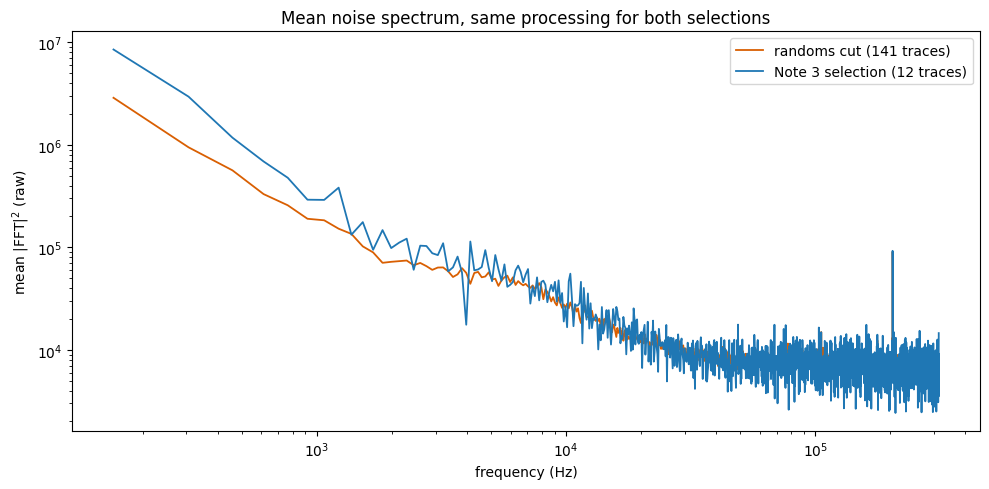

band (Hz)            randoms cut   Note 3 sel.   ratio
    1000-3000          9.35e+04      1.47e+05    0.64
    3000-10000         4.41e+04      5.24e+04    0.84
   10000-50000         1.16e+04      1.21e+04    0.96
   50000-150000        7.83e+03      7.55e+03    1.04
  250000-310000         6.8e+03      6.94e+03    0.98


In [6]:
rows = [r for r in csv.DictReader(open(REPO / "data_analysis" / "R76" / "notebooks" / "good_noise_traces.csv"))
        if int(r["channel"]) == CHANNEL and int(r["group"]) == DETECTOR]
old_ids = [f"{r['event']}_{r['group']}_Phonon_4096" for r in rows]
_, old_pulses = pio.load_channel_batch(cdms, old_ids, CHANNEL)
old_raw = pq.power_spectrum(processed(old_pulses), config_500)
print(f"Note 3 selection, Detector {DETECTOR} / Channel {CHANNEL}: {len(old_ids)} traces; "
      f"bstd (500 samples, glitch skipped) median {np.median(pq.bstd(old_pulses, config_500)):.2f} counts")

fig, ax = plt.subplots(figsize=(10, 5))
ax.loglog(freqs[1:], raw.mean(axis=0)[1:], color="#d95f02", linewidth=1.3, label=f"randoms cut ({raw.shape[0]} traces)")
ax.loglog(freqs[1:], old_raw.mean(axis=0)[1:], color="#1f77b4", linewidth=1.3, label=f"Note 3 selection ({old_raw.shape[0]} traces)")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel(r"mean $|\mathrm{FFT}|^2$ (raw)")
ax.legend()
ax.set_title("Mean noise spectrum, same processing for both selections")
fig.tight_layout()
plt.show()

bands = [(1e3, 3e3), (3e3, 1e4), (1e4, 5e4), (5e4, 1.5e5), (2.5e5, 3.1e5)]
print(f"{'band (Hz)':<18}{'randoms cut':>14}{'Note 3 sel.':>14}{'ratio':>8}")
for lo, hi in bands:
    m = (freqs >= lo) & (freqs < hi)
    a, b = raw.mean(axis=0)[m].mean(), old_raw.mean(axis=0)[m].mean()
    print(f"{lo:>8.0f}-{hi:<8.0f}{a:>14.3g}{b:>14.3g}{a / b:>8.2f}")

## Next steps

- Describe what differs between the two spectra, and decide whether the sharp peaks of Note 7 (which Note 7 traced to two Detector 1 traces) are present here.
- Repeat for Channels 1 to 3, and for Detector 1.
- Add the other dumps of the series (F0002 to F0005) with `pio.load_channel_batch_multi`, and check that the trigger-label assumption holds there.
- When this becomes a note: it supersedes Note 3, so the Note 3 row gets the Superseded status and a link to the new note.

## 6. The other channels

So far everything is Channel 0. Here the same recipe (500-sample pretrigger, Tight excursion band, `log10(bstd) < 0.5`, then `randoms`, then the same baseline subtraction, glitch trim and FFT) is applied to every channel of Detector 0, so the spectra can be compared channel by channel.

**Caution.** The Tight band and the `bstd < 0.5` threshold were chosen by looking at Channel 0. Other channels may have a different noise level or pulse shape, so the cut may keep very few traces, or the wrong ones. Look at the counts in the table before trusting a spectrum, and look at the traces of any channel that keeps few.

Detector 0 has 4 channels
channel  name        traces   quiet  randoms  bstd median


C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\1602808048.py:13: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  sel = quiet & pc.randoms(trig)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\1602808048.py:15: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  print(f"{ch:<9}{pch.channel_name(DETECTOR, ch):<10}{len(p):>8}{quiet.sum():>8}{sel.sum():>9}{med:>13.2f}")
C:\Users\villanoa\Research\NSDF-Data\python\pulse_channels.py:83: UserWarning: channel_info is marke

0        Side2pC       1517     179      141         1.51


1        Side2pF       1517     130      107         1.63


C:\Users\villanoa\Research\NSDF-Data\python\pulse_quantities.py:105: RuntimeWarning: invalid value encountered in divide
  return max_deviation(pulses, config) / pretrigger_std(pulses, config)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\1602808048.py:12: RuntimeWarning: divide by zero encountered in log10
  quiet = pc.excursion_band(p, config_500) & (np.log10(b) < 0.5)


2        Side1pC       1517       0        0          nan
3        Side1pF       1517     144      109         1.56


C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\1602808048.py:22: UserWarning: channel_label is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  label = pch.channel_label(DETECTOR, ch)
C:\Users\villanoa\Research\NSDF-Data\python\pulse_channels.py:89: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = channel_info(detector, channel)


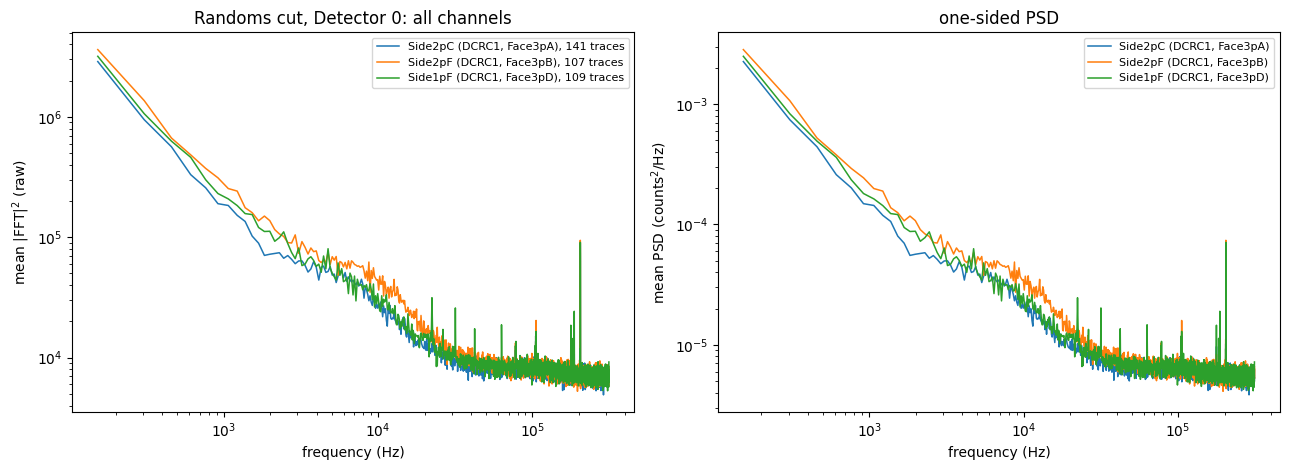

In [7]:
import pulse_channels as pch    # (detector, channel) -> detector channel name; see section 7

det_ids = pio.filter_by_detector(cdms.get_detector_ids(), DETECTOR)
n_channels = len(cdms.get_detector_channels(det_ids[0]))
print(f"Detector {DETECTOR} has {n_channels} channels")

by_channel = {}
print(f"{'channel':<9}{'name':<10}{'traces':>8}{'quiet':>8}{'randoms':>9}{'bstd median':>13}")
for ch in range(n_channels):
    _, p = pio.load_channel_batch(cdms, det_ids, ch)
    b = pq.bstd(p, config_500)
    quiet = pc.excursion_band(p, config_500) & (np.log10(b) < 0.5)
    sel = quiet & pc.randoms(trig)
    med = np.median(b[sel]) if sel.any() else float("nan")
    print(f"{ch:<9}{pch.channel_name(DETECTOR, ch):<10}{len(p):>8}{quiet.sum():>8}{sel.sum():>9}{med:>13.2f}")
    if sel.sum() >= 2:
        f = processed(p[sel])
        by_channel[ch] = pq.power_spectrum(f, config_500)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ch, r in by_channel.items():
    label = pch.channel_label(DETECTOR, ch)
    axes[0].loglog(freqs[1:], r.mean(axis=0)[1:], linewidth=1.1, label=f"{label}, {r.shape[0]} traces")
    axes[1].loglog(freqs[1:], (r * (2 * config_500.sample_period_s / n)).mean(axis=0)[1:], linewidth=1.1, label=label)
axes[0].set_ylabel(r"mean $|\mathrm{FFT}|^2$ (raw)")
axes[1].set_ylabel("mean PSD (counts$^2$/Hz)")
for ax in axes:
    ax.set_xlabel("frequency (Hz)")
    ax.legend(fontsize=8)
axes[0].set_title(f"Randoms cut, Detector {DETECTOR}: all channels")
axes[1].set_title("one-sided PSD")
fig.tight_layout()
plt.savefig(f'figures/allchan-psd-{DUMP}.png')
plt.show()

## 7. Which detector channel is which?

The dump labels its data by **detector index** (0, 1, 2) and **channel index** (0 to 3). Everything above used Detector 0 / Channel 0. To say which physical channel that is, and what the other eleven are, we need to connect those indices to the hardware.

The plan of this section:

1. the original channel table from the UMN Run 76 summary, as published;
2. our interpretation of it, and the evidence for each step;
3. a simplified table of the mapping, which the rest of the notebook uses.

The short version: the dump's three "detectors" are not three detectors. They are three 4-channel readout boards (DCRC1, DCRC3, DCRC4) of **one** two-sided detector, read out in that order.

### 7.1 The original table

The *Setup* table of the [Run 76 summary](https://villano-lab.github.io/R76Analysis/cdms/k100/run_summary/run_76.html) on the UMN wiki, as published (copied by hand; the merged Cable and DCRC cells are shown once per group):

| Tower input | Cable | DCRC (2-sided) | Label | HV output, Side 1 readout | HV output, Side 2 readout |
|---|---|---|---|---|---|
| Face5pA | Cable 2 (includes LEDs and accessories), HV CONN1 | DCRC3 | Side1pE | HV1 pA | - |
| Face5pB | | | Side1pB | HV1 pB | - |
| Face5pC | | | Side1pD | HV1 pC | - |
| Face5pD | | | Side2pE | - | HV2 pD |
| Face3pA | Cable 1, HV CONN2 | DCRC1 | Side2pC | - | HV2 pA |
| Face3pB | | | Side2pF | - | HV2 pB |
| Face3pC | | | Side1pC | HV2 pC | - |
| Face3pD | | | Side1pF | HV2 pD | - |
| Face2pA | Cable 3, HV CONN3 | DCRC4 | Side2pB | - | HV1 pA |
| Face2pB | | | Side2pA | - | HV1 pB |
| Face2pC | | | Side1pA | HV2 pB | - |
| Face2pD | | | Side2pD | - | HV1 pD |

What the table does and does not tell us: it lists 12 channels on 3 DCRC boards (4 per board), each with a `Label` (the detector channel, `Side1pA` to `Side1pF` and `Side2pA` to `Side2pF`). It does not say which board the dump calls detector 0, 1 or 2, or in what order the four channels of a board are stored. The HV columns are typo-prone (for example `HV2 pB` and `HV2 pD` each appear twice), so they are not used.

### 7.2 Our interpretation

Three steps, each with its evidence and how sure we are.

**Step 1. The three "detectors" are the three DCRC boards; all 12 channels belong to one two-sided detector.** The table lists three DCRC boards of 4 channels each, and the dump has 3 detectors of 4 channels each. The `Label` column (`Side1pA` to `Side2pF`) names the real channels of the one detector. *Confident.*

**Step 2. Detector index 0, 1, 2 = DCRC1, DCRC3, DCRC4 (ascending board number).** This comes from the run configuration (the ODB) stored at the start of a raw MIDAS file. The ODB and the raw file are not on NSDF for series `07221203_2025`, so this was worked out on a different Run 76 file we have locally, `07220916_2200_F0001.mid.gz` (16 Sep 2022):

- The ODB (`/Equipment/Tower01/Settings`) has DCRC1, DCRC3 and DCRC4 enabled, and DCRC2, DCRC5 and DCRC6 disabled. This agrees with the table.
- Each event in the raw file holds three records, one per board. Every record header carries a code whose low byte is `0x09`, `0x0B`, `0x0C`, in that order, in all 286 data banks of the file.
- 9, 11, 12 are the board numbers 1, 3, 4 plus 8. We read the code as the board number plus a constant offset, which gives detector 0 = DCRC1, 1 = DCRC3, 2 = DCRC4.

*Probable, not proven:* the offset of 8 is inferred from three numbers fitting, nothing in the file states it, and the evidence is from a different series than ours. Settle it by finding the raw file or ODB for `07221203_2025` (the logger writes under `/data/chocula/k100/midasraw/` on the UMN hosts).

**Step 3. Channel index 0 to 3 within a board follows the table's row order (A, B, C, D).** An assumption: each record holds 4 channels of 4096 samples, but we have not checked their order against the ODB. *Unverified.*

**Channel names** come from the `Label` column, not the HV columns, which repeat entries and are typo-prone.

The mapping is kept in one place, the library module `python/pulse_channels.py`, tagged *under development* so that every use warns. If step 2 or 3 turns out wrong, only `DCRC_OF_DETECTOR` or `ROWS` in that file change, and every notebook follows.

### 7.3 Simplified table: dump indices to detector channels

This is the mapping used from here on (provisional, see 7.2). "Detector 0 / Channel 0" of the earlier sections is the first row. In code: `pch.channel_name(0, 0)` gives `'Side2pC'`, `pch.channel_label(0, 0)` adds the board and tower input, and `pch.find_channel('Side2pC')` goes the other way.

| Detector index | Channel index | DCRC board | Tower input | Detector channel (Label) |
|:-:|:-:|:-:|:-:|:-:|
| 0 | 0 | DCRC1 | Face3pA | Side2pC |
| 0 | 1 | DCRC1 | Face3pB | Side2pF |
| 0 | 2 | DCRC1 | Face3pC | Side1pC |
| 0 | 3 | DCRC1 | Face3pD | Side1pF |
| 1 | 0 | DCRC3 | Face5pA | Side1pE |
| 1 | 1 | DCRC3 | Face5pB | Side1pB |
| 1 | 2 | DCRC3 | Face5pC | Side1pD |
| 1 | 3 | DCRC3 | Face5pD | Side2pE |
| 2 | 0 | DCRC4 | Face2pA | Side2pB |
| 2 | 1 | DCRC4 | Face2pB | Side2pA |
| 2 | 2 | DCRC4 | Face2pC | Side1pA |
| 2 | 3 | DCRC4 | Face2pD | Side2pD |

Side 1 has the channels pA to pF, and so does Side 2. Each of the 12 names appears exactly once. The code cell below prints the same table from the library and checks it.

### 7.4 Where the channels are on the detector

![Channel layout of one face of the detector](figures/channelLayout.png)

*Layout of the phonon channels on one face of the detector, with the x and y axes of the detector. A and B are the two outer rings, C, D and E are the three sectors of the middle region (C at the top, D at the bottom, E at the right), and F is the centre disc. Each face has this same layout: the letter is the last character of the channel name, so `A` is `Side1pA` on face 1 and `Side2pA` on face 2. Figure from the R76 thermal-neutron-peaks paper project (`figures/channelLayout.png`); the wiki's source-position figure, `r76_r75_source_positions.png`, shows both faces side by side.*

For example, our Detector 0 / Channel 0 is `Side2pC`: the C sector of face 2. Channel 2 of the same board is `Side1pC`, the C sector of face 1, and channel 3 is `Side1pF`, the centre disc of face 1.

In [8]:
# The mapping lives in the library (python/pulse_channels.py), so every notebook uses the same one.
# Step 2 of 7.2 (detector index -> DCRC board) is pch.DCRC_OF_DETECTOR, step 3 (channel order in a board)
# is the row order of pch.ROWS.
import pulse_channels as pch

print(f"{'det':<5}{'chan':<6}{'DCRC':<8}{'tower input':<13}{'detector channel':<18}")
for c in pch.all_channels():
    print(f"{c.detector:<5}{c.channel:<6}{c.dcrc:<8}{c.tower_input:<13}{c.name:<18}")

assert len({c.name for c in pch.all_channels()}) == 12, "each detector channel should appear once"
print("\nExample: Detector 0 / Channel 0 is", pch.channel_label(0, 0))

det  chan  DCRC    tower input  detector channel  
0    0     DCRC1   Face3pA      Side2pC           
0    1     DCRC1   Face3pB      Side2pF           
0    2     DCRC1   Face3pC      Side1pC           
0    3     DCRC1   Face3pD      Side1pF           
1    0     DCRC3   Face5pA      Side1pE           
1    1     DCRC3   Face5pB      Side1pB           
1    2     DCRC3   Face5pC      Side1pD           
1    3     DCRC3   Face5pD      Side2pE           
2    0     DCRC4   Face2pA      Side2pB           
2    1     DCRC4   Face2pB      Side2pA           
2    2     DCRC4   Face2pC      Side1pA           
2    3     DCRC4   Face2pD      Side2pD           

Example: Detector 0 / Channel 0 is Side2pC (DCRC1, Face3pA)


C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\2263511930.py:7: UserWarning: all_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  for c in pch.all_channels():
C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\2263511930.py:10: UserWarning: all_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  assert len({c.name for c in pch.all_channels()}) == 12, "each detector channel should appear once"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\2263511930.py:11: UserWarning: channel_label is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; no

## 8. Noise spectra of all 12 channels

One tile per channel: rows are the three readout boards (detector index 0, 1, 2 = DCRC1, DCRC3, DCRC4) and columns are the four channels of each board, so tile `(row, column)` is `Detector row / Channel column`. Each tile shows the one-sided PSD of the randoms-cut traces of that channel (the mean, with the 16th to 84th percentile band of the individual traces), with the channel name from section 7 as its title and the number of traces used in the corner. Side 1 channels are blue and Side 2 channels are orange. All tiles share the same axes, so levels can be compared by eye.

**Caution.** The cut is the one tuned on Detector 0 / Channel 0 (Tight excursion band, `log10(bstd) < 0.5`, then `randoms`), applied unchanged to every channel. A channel that keeps few traces has a noisier tile, and a tile is left empty when fewer than 2 traces survive. The channel names are provisional (see 7.2).

C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\354197989.py:3: UserWarning: all_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  detectors = sorted({c.detector for c in pch.all_channels()})
C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\354197989.py:16: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  sel = quiet & pc.randoms(trig_d)


C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\354197989.py:29: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  info = pch.channel_info(det, ch)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_31612\354197989.py:44: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  ax.set_ylabel(f"Detector {det} ({pch.channel_info(det, 0).dcrc})\nPSD (counts$^2$/Hz)")


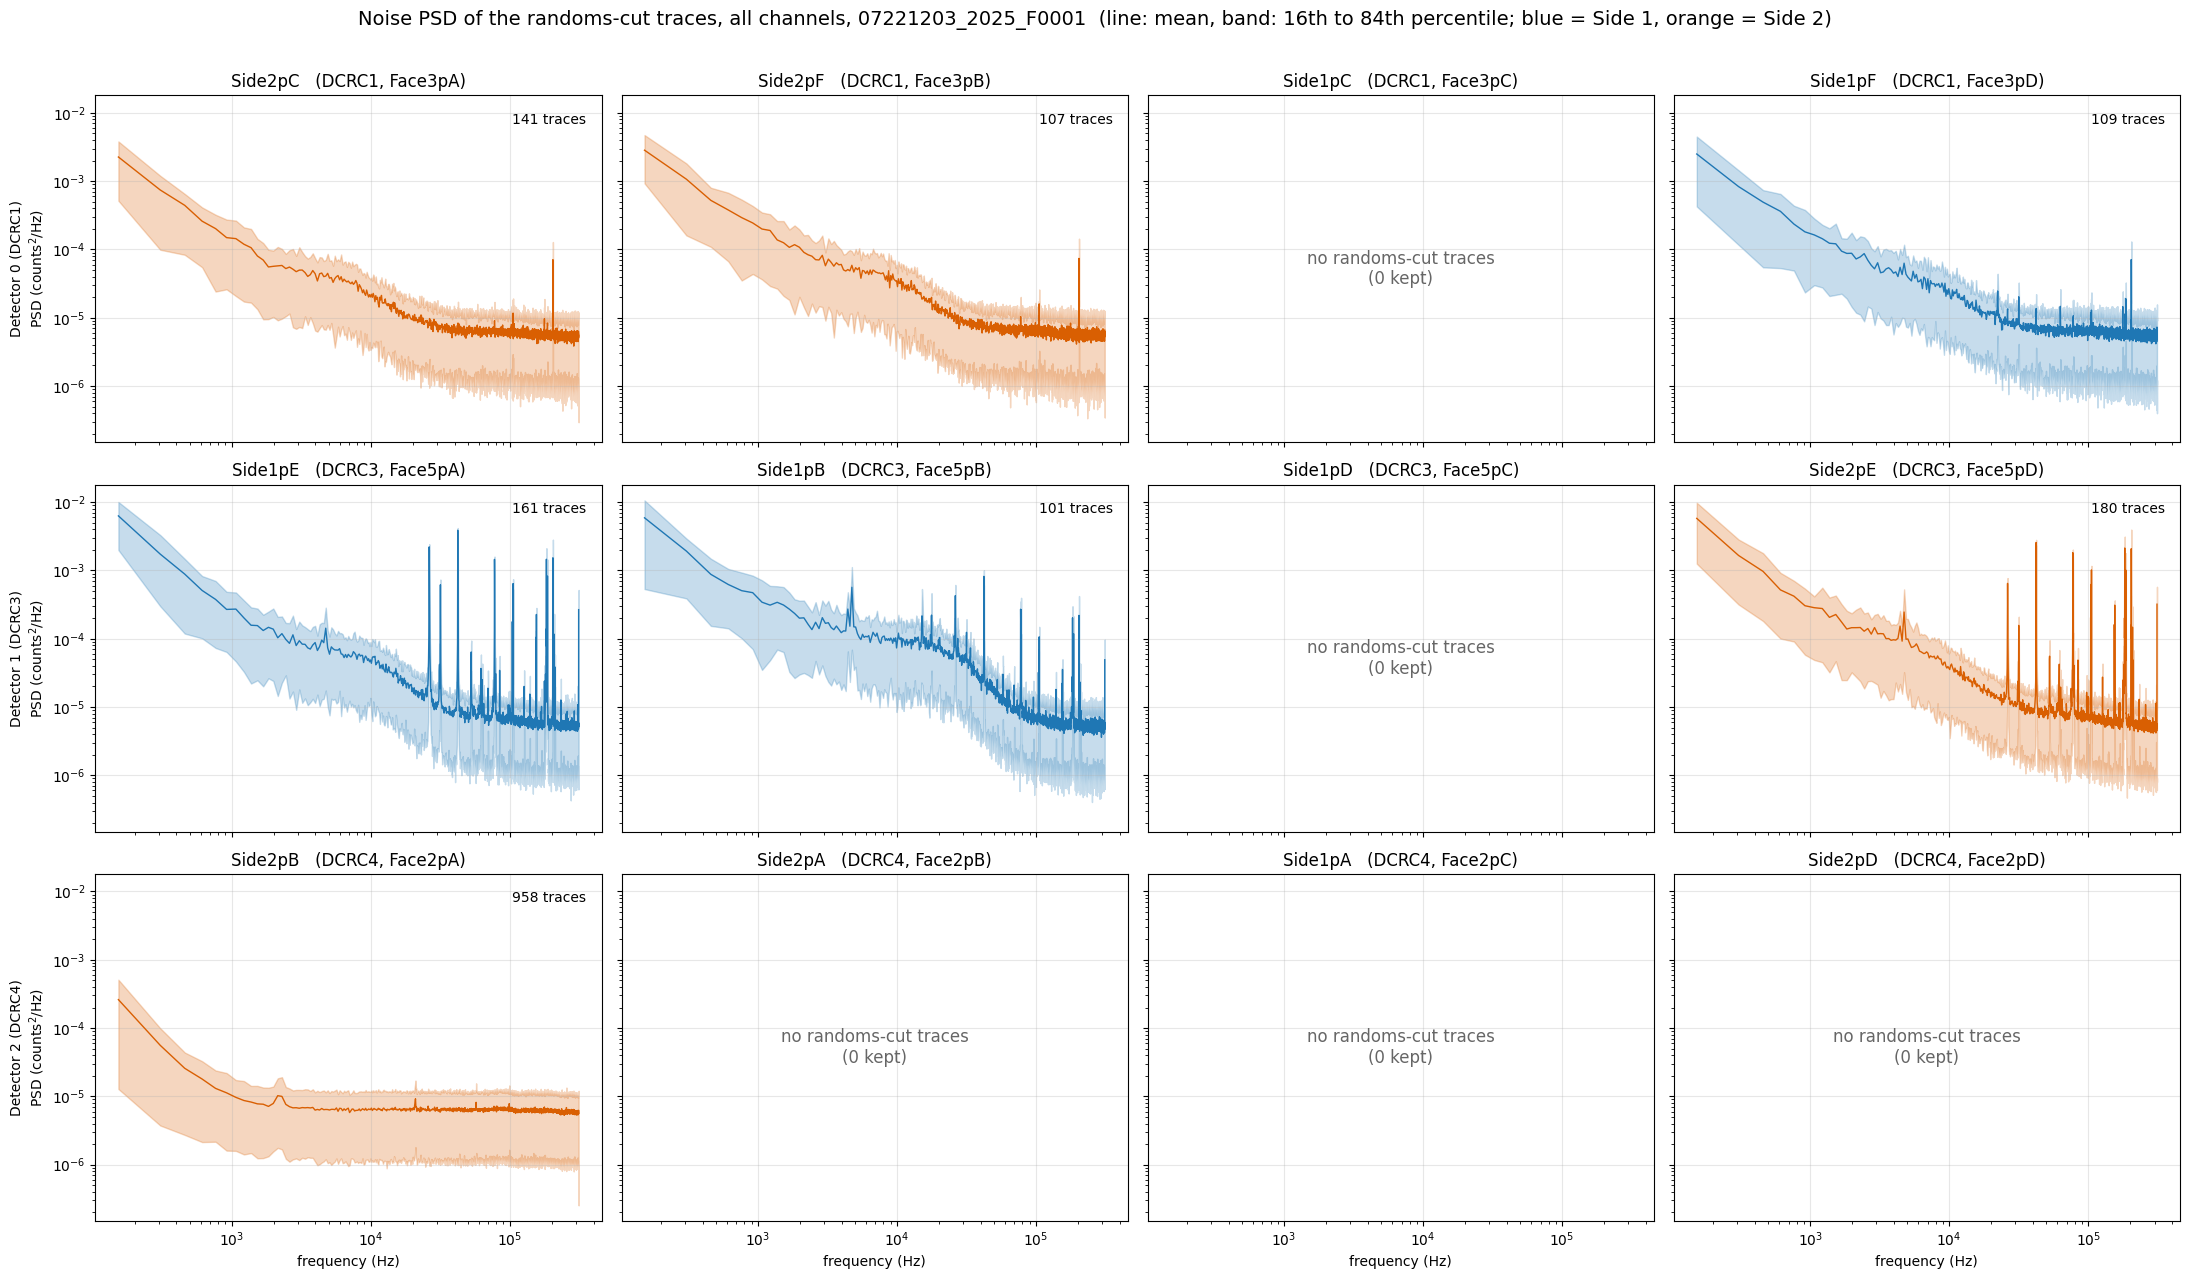

In [9]:
import pulse_channels as pch

detectors = sorted({c.detector for c in pch.all_channels()})
n_chan = 4

# One-sided PSD (counts^2/Hz) of the randoms-cut traces of every channel
tiles = {}    # (detector, channel) -> (n traces kept, mean, 16th, 84th percentile); the spectra are None if < 2 traces
for det in detectors:
    ids_d = pio.filter_by_detector(cdms.get_detector_ids(), det)
    trig_d = pio.trigger_types(cdms, ids_d)
    for ch in range(n_chan):
        _, p = pio.load_channel_batch(cdms, ids_d, ch)
        with np.errstate(all="ignore"):          # a dead channel has zero baseline scatter
            b = pq.bstd(p, config_500)
            quiet = pc.excursion_band(p, config_500) & (np.log10(b) < 0.5)
        sel = quiet & pc.randoms(trig_d)
        if sel.sum() >= 2:
            psd_ch = pq.power_spectrum(processed(p[sel]), config_500) * (2 * config_500.sample_period_s / n)
            lo, hi = np.percentile(psd_ch, [16, 84], axis=0)
            tiles[(det, ch)] = (int(sel.sum()), psd_ch.mean(axis=0), lo, hi)
        else:
            tiles[(det, ch)] = (int(sel.sum()), None, None, None)

side_colour = {1: "#1f77b4", 2: "#d95f02"}
fig, axes = plt.subplots(len(detectors), n_chan, figsize=(22, 13), sharex=True, sharey=True)
for det in detectors:
    for ch in range(n_chan):
        ax = axes[det, ch]
        info = pch.channel_info(det, ch)
        n_kept, mean, lo, hi = tiles[(det, ch)]
        ax.set_title(f"{info.name}   ({info.dcrc}, {info.tower_input})", fontsize=12)
        if mean is None:
            ax.text(0.5, 0.5, f"no randoms-cut traces\n({n_kept} kept)", transform=ax.transAxes,
                    ha="center", va="center", color="0.4", fontsize=12)
        else:
            colour = side_colour[info.side]
            ax.fill_between(freqs[1:], lo[1:], hi[1:], color=colour, alpha=0.25)
            ax.plot(freqs[1:], mean[1:], color=colour, linewidth=1.0)
            ax.text(0.97, 0.95, f"{n_kept} traces", transform=ax.transAxes, ha="right", va="top", fontsize=10)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.grid(True, which="major", alpha=0.3)
        if ch == 0:
            ax.set_ylabel(f"Detector {det} ({pch.channel_info(det, 0).dcrc})\nPSD (counts$^2$/Hz)")
        if det == detectors[-1]:
            ax.set_xlabel("frequency (Hz)")
fig.suptitle(f"Noise PSD of the randoms-cut traces, all channels, {DUMP}  "
             "(line: mean, band: 16th to 84th percentile; blue = Side 1, orange = Side 2)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(f"figures/allchan-tiles-{DUMP}.png", dpi=110)
plt.show()

### 8.1 What the tiles show (this dump only)

- **7 of the 12 channels keep randoms-cut traces; 5 tiles are empty.** Channel 2 of DCRC1 (`Side1pC`) and of DCRC3 (`Side1pD`) is empty, and so are channels 1, 2 and 3 of DCRC4. DCRC4's one filled tile, `Side2pB`, uses 958 traces, nearly every event, and has a flat spectrum with none of the low-frequency rise of the other tiles. The cut is not selecting anything there, so that tile is a white-noise floor, not a quiet subset.
- **This fits the run configuration (ODB) we read for series `07220916_2200`:** the QET bias is zero on channel 2 of both DCRC1 and DCRC3 and on all four channels of DCRC4, and DCRC4 channel 0 has its feedback disabled. Those are the channels that come out empty or flat here. This supports step 3 of 7.2 (the channel order within a board) and detector 2 = DCRC4. It does not tell DCRC1 from DCRC3, and the ODB is from a different series, so treat it as supporting evidence, not proof.
- **Spectral lines differ by board.** Both filled channels of Detector 1 (DCRC3) show many narrow lines between about 25 kHz and 300 kHz. The three filled channels of Detector 0 (DCRC1) show one strong line near 200 kHz and few others. Above 100 kHz the continuum of every filled tile except DCRC4's falls to a similar floor of about 6e-6 counts²/Hz.